# Avance 4.8. Modelos alternativos

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

En el Avance 3 construimos un baseline: una regresión logística sobre las 111 características del Avance 2. Ahora la pregunta es si otro algoritmo aprende mejor de esos mismos datos. En este notebook vamos a:

1. Entrenar siete modelos individuales con algoritmos distintos y compararlos con las mismas métricas y los mismos pliegues.
2. Elegir a los mejores para ajustarlos: los dos primeros y, si empata con el segundo, también el tercero.
3. Ajustar sus hiperparámetros con una búsqueda amplia.
4. Elegir el modelo individual final, mirando la métrica principal y también el costo, la interpretabilidad y el comportamiento en los puntos de operación.

La tarea no cambia: tamizaje binario con PTB-XL 1.0.3. Clase 1 (cardiopatía) si el ECG tiene algún código `MI`, `STTC`, `CD` o `HYP`; clase 0 (normal) si solo tiene `NORM`.

## 1. Configuración y datos

Partimos de la tabla del Avance 2 (`outputs/avance2_fusion/`). Si no existe, la primera celda ejecuta `Avance2.8.ipynb` para generarla (unos 5 minutos).

In [1]:
import os

N_JOBS = min(12, os.cpu_count())
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import json
import platform
import sys
import time
import warnings
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed
from scipy.stats import loguniform, t as student_t, uniform
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from ecg_experiment.intervals import metric_intervals, paired_auroc_difference
from ecg_experiment.paths import to_stored

AVANCE2 = Path(os.environ.get("AVANCE2_OUT", ROOT / "outputs/avance2_fusion"))
OUT = Path(os.environ.get("AVANCE4_OUT", ROOT / "outputs/avance4_modelos"))
OUT.mkdir(parents=True, exist_ok=True)
TABLE = AVANCE2 / "ptbxl_caracteristicas_seleccionadas.csv"

if not TABLE.exists():
    import nbformat
    from nbclient import NotebookClient
    print("No está la tabla del Avance 2; se ejecuta Avance2.8.ipynb para generarla (unos 5 minutos).")
    avance2 = nbformat.read(ROOT / "notebooks/Avance2.8.ipynb", as_version=4)
    NotebookClient(avance2, timeout=None, resources={"metadata": {"path": str(ROOT / "notebooks")}}).execute()

SEED = 42
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="A worker stopped")
os.environ["PYTHONWARNINGS"] = "ignore"
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind", rc={"figure.dpi": 110, "axes.titlesize": 11})
VERSIONS = {p: version(p) for p in ("numpy", "pandas", "scikit-learn", "scipy", "seaborn", "matplotlib")}
print(f"Python {platform.python_version()} | " + " | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

Python 3.11.13 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.17.1 | seaborn 0.13.2 | matplotlib 3.11.2


In [2]:
data = pd.read_csv(TABLE, index_col="ecg_id")
dictionary = pd.read_csv(AVANCE2 / "variables_finales.csv").set_index("variable")
FEATURES = list(dictionary.index)
assert data[FEATURES].notna().all().all()

X, y = data[FEATURES], data.target.astype(int)
patients, folds = data.patient_id.to_numpy(), data.strat_fold
train, val, test = (data.split == s for s in ("train", "val", "test"))
X_train, y_train = X[train], y[train]
CV = PredefinedSplit(folds[train].to_numpy())
FOLD_TRAIN = folds[train].to_numpy()

display(data.groupby("split", sort=False).agg(ECG=("target", "size"), pacientes=("patient_id", "nunique"),
                                              cardiopatia_pct=("target", lambda t: 100 * t.mean())).loc[["train", "val", "test"]].round(1))
print(f"{len(FEATURES)} características por ECG")

,ECG,pacientes,cardiopatia_pct
split,,,
train,17083,14822,57.6
val,2146,1917,57.4
test,2158,1877,57.7


111 características por ECG


Usamos las mismas particiones del Avance 3, que mantienen a cada paciente en un solo pliegue:

- Entrenamiento (pliegues 1 a 8). Aquí se toman todas las decisiones con validación cruzada: se entrena con siete pliegues y se evalúa en el octavo, ocho veces.
- Validación (pliegue 9). Sirve para comparar los modelos ya ajustados con ECG que ninguna búsqueda vio.
- Prueba (pliegue 10). En este notebook se usa una sola vez, al final, con el modelo ya elegido.

## 2. Cómo vamos a comparar

Mantenemos las métricas que definimos en el Avance 3:

| Métrica | Qué mide | Papel |
| --- | --- | --- |
| AUROC | Qué tan bien ordena el modelo a los ECG con cardiopatía por encima de los normales. 0.5 es azar, 1.0 es perfecto. | Métrica principal. Con ella se ordenan los modelos y se eligen los hiperparámetros. |
| Sensibilidad con 90% de especificidad | Fracción de cardiopatías detectadas si solo derivamos al 10% de los normales. | Punto de operación del servicio. |
| Especificidad con 95% de sensibilidad | Fracción de normales que no se derivan si queremos detectar al 95% de las cardiopatías. | Cuánto trabajo le ahorra el modelo al cardiólogo. |
| AUPRC | Precisión promedio. | Se reporta, pero depende de la prevalencia de PTB-XL. |
| Tiempo | Segundos para entrenar en siete pliegues y milisegundos para puntuar 1,000 ECG. | Costo computacional. |

Las métricas de desempeño se calculan sobre las predicciones out-of-fold: cada ECG de entrenamiento recibe la puntuación de un modelo que no lo vio. Los ocho pliegues se entrenan en paralelo, cada uno con un solo hilo, para que los tiempos sean comparables entre modelos.

In [3]:
def specificity_at_sensitivity(y_true, score, target: float = 0.95) -> float:
    """Mayor especificidad alcanzable con una sensibilidad de al menos `target`."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(1 - fpr[tpr >= target].min())


def sensitivity_at_specificity(y_true, score, target: float = 0.90) -> float:
    """Mayor sensibilidad alcanzable con una especificidad de al menos `target`."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= 1 - target].max())


def summarize(y_true, score) -> dict[str, float]:
    """Las cuatro métricas de desempeño del avance."""
    return {"AUROC": roc_auc_score(y_true, score), "sens_con_esp_90": sensitivity_at_specificity(y_true, score),
            "esp_con_sens_95": specificity_at_sensitivity(y_true, score), "AUPRC": average_precision_score(y_true, score)}


def model_score(model, features: pd.DataFrame) -> np.ndarray:
    """Probabilidad de cardiopatía, o la distancia a la frontera si el modelo no da probabilidades."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.decision_function(features)


def fit_fold(model, fold: int) -> dict:
    """Entrena con siete pliegues, puntúa el octavo y mide los tiempos."""
    fit_rows, held_rows = FOLD_TRAIN != fold, FOLD_TRAIN == fold
    model = clone(model)
    start = time.perf_counter()
    model.fit(X_train[fit_rows], y_train[fit_rows])
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    score = model_score(model, X_train[held_rows])
    predict_seconds = time.perf_counter() - start
    return {"fold": fold, "score": score, "fit_s": fit_seconds, "ms_por_1000": 1000 * predict_seconds / held_rows.sum() * 1000}


def cross_validate_model(model) -> dict:
    """Predicciones out-of-fold, AUROC por pliegue y tiempos de un modelo."""
    results = Parallel(n_jobs=min(N_JOBS, 8))(delayed(fit_fold)(model, f) for f in np.unique(FOLD_TRAIN))
    oof = np.empty(len(FOLD_TRAIN))
    for r in results:
        oof[FOLD_TRAIN == r["fold"]] = r["score"]
    fold_auroc = [roc_auc_score(y_train[FOLD_TRAIN == r["fold"]], r["score"]) for r in results]
    return {"oof": oof, "AUROC_desv_pliegues": float(np.std(fold_auroc)), "entrenamiento_s": float(np.mean([r["fit_s"] for r in results])),
            "prediccion_ms_por_1000": float(np.mean([r["ms_por_1000"] for r in results]))}

## 3. Los siete candidatos

Elegimos algoritmos que aprenden de formas distintas, para que la comparación diga algo sobre el tipo de frontera que necesitan los datos:

| Modelo | Cómo decide | Por qué lo incluimos |
| --- | --- | --- |
| Regresión logística | Una frontera lineal; cada característica suma o resta al log-odds. | Es el baseline del Avance 3 (`C = 0.1`). Cualquier alternativa tiene que superarlo. |
| Análisis discriminante lineal (LDA) | También lineal, pero supone que cada clase es una nube normal con la misma covarianza. | Otra forma de llegar a una frontera lineal, sin optimización iterativa. |
| Naive Bayes gaussiano | Combina la probabilidad de cada característica por separado, como si fueran independientes. | Muy rápido; sirve para ver cuánto pesa la correlación entre características. |
| k vecinos más cercanos (kNN) | Mira a los ECG de entrenamiento más parecidos y vota. | No supone ninguna forma de frontera; depende solo de la distancia. |
| Árbol de decisión | Reglas del tipo "si QRS > x y T < z". | El modelo más fácil de explicar a un cardiólogo. |
| Máquina de soporte vectorial (SVM, kernel RBF) | Una frontera no lineal con el máximo margen entre clases. | Suele funcionar bien con datos tabulares estandarizados de este tamaño. |
| Red neuronal (perceptrón multicapa, MLP) | Capas de neuronas que combinan las características de forma no lineal. | Permite ajustar arquitectura, función de activación y tasa de aprendizaje. |

Una aclaración sobre lo que no entra. Random forest y gradient boosting son ensambles, porque combinan cientos de árboles, y este avance pide modelos individuales. Quedan para el siguiente avance. Aun así, incluimos el gradient boosting del Avance 3 como línea de referencia, para saber a qué distancia queda cada modelo individual de un ensamble.

En esta primera ronda cada modelo usa los valores por defecto de scikit-learn. Hay solo dos excepciones: la regresión logística usa el `C = 0.1` que ya se eligió en el Avance 3, y la SVM no calcula probabilidades, así que su puntuación es la distancia a la frontera (el AUROC solo necesita ordenar a los ECG, no probabilidades).

In [4]:
CANDIDATES = {
    "Regresión logística": LogisticRegression(C=0.1, max_iter=5000),
    "LDA": LinearDiscriminantAnalysis(),
    "Naive Bayes gaussiano": GaussianNB(),
    "kNN": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEED),
    "SVM (RBF)": SVC(),
    "Red neuronal (MLP)": MLPClassifier(random_state=SEED),
}
REFERENCE = {"Gradient boosting (ensamble, referencia)": HistGradientBoostingClassifier(random_state=SEED)}

default_runs = {}
for name, model in {**CANDIDATES, **REFERENCE}.items():
    default_runs[name] = cross_validate_model(model)
    print(f"{name:42s} AUROC {roc_auc_score(y_train, default_runs[name]['oof']):.4f} | entrenamiento {default_runs[name]['entrenamiento_s']:6.1f} s")

Regresión logística                        AUROC 0.9352 | entrenamiento    0.4 s


LDA                                        AUROC 0.9241 | entrenamiento    0.9 s


Naive Bayes gaussiano                      AUROC 0.9140 | entrenamiento    0.2 s


kNN                                        AUROC 0.8989 | entrenamiento    0.1 s


Árbol de decisión                          AUROC 0.8136 | entrenamiento    1.9 s


SVM (RBF)                                  AUROC 0.9509 | entrenamiento    6.8 s


Red neuronal (MLP)                         AUROC 0.9340 | entrenamiento    8.6 s


Gradient boosting (ensamble, referencia)   AUROC 0.9549 | entrenamiento    1.1 s


In [5]:
def comparison_table(runs: dict[str, dict]) -> pd.DataFrame:
    """Métricas out-of-fold y tiempos, ordenados por AUROC."""
    rows = {name: {**summarize(y_train, r["oof"]), "AUROC_desv_pliegues": r["AUROC_desv_pliegues"],
                   "entrenamiento_s": r["entrenamiento_s"], "prediccion_ms_por_1000": r["prediccion_ms_por_1000"]} for name, r in runs.items()}
    table = pd.DataFrame(rows).T.sort_values("AUROC", ascending=False)
    return table[["AUROC", "AUROC_desv_pliegues", "sens_con_esp_90", "esp_con_sens_95", "AUPRC", "entrenamiento_s", "prediccion_ms_por_1000"]]


default_table = comparison_table(default_runs)
rank = default_table.drop(index=list(REFERENCE)).AUROC.rank(ascending=False).astype(int).astype(str)
default_table.insert(0, "puesto", rank.reindex(default_table.index).fillna("referencia"))
display(default_table.round(3))

,puesto,AUROC,AUROC_desv_pliegues,sens_con_esp_90,esp_con_sens_95,AUPRC,entrenamiento_s,prediccion_ms_por_1000
"Gradient boosting (ensamble, referencia)",referencia,0.955,0.004,0.868,0.740,0.969,1.092,4.801
SVM (RBF),1,0.951,0.004,0.861,0.712,0.967,6.823,266.106
Regresión logística,2,0.935,0.004,0.826,0.620,0.957,0.359,1.535
Red neuronal (MLP),3,0.934,0.006,0.822,0.602,0.957,8.553,2.084
LDA,4,0.924,0.005,0.798,0.563,0.949,0.947,1.526
Naive Bayes gaussiano,5,0.914,0.005,0.763,0.559,0.935,0.210,3.552
kNN,6,0.899,0.008,0.737,0.000,0.916,0.116,87.763
Árbol de decisión,7,0.814,0.012,0.000,0.000,0.800,1.934,1.477


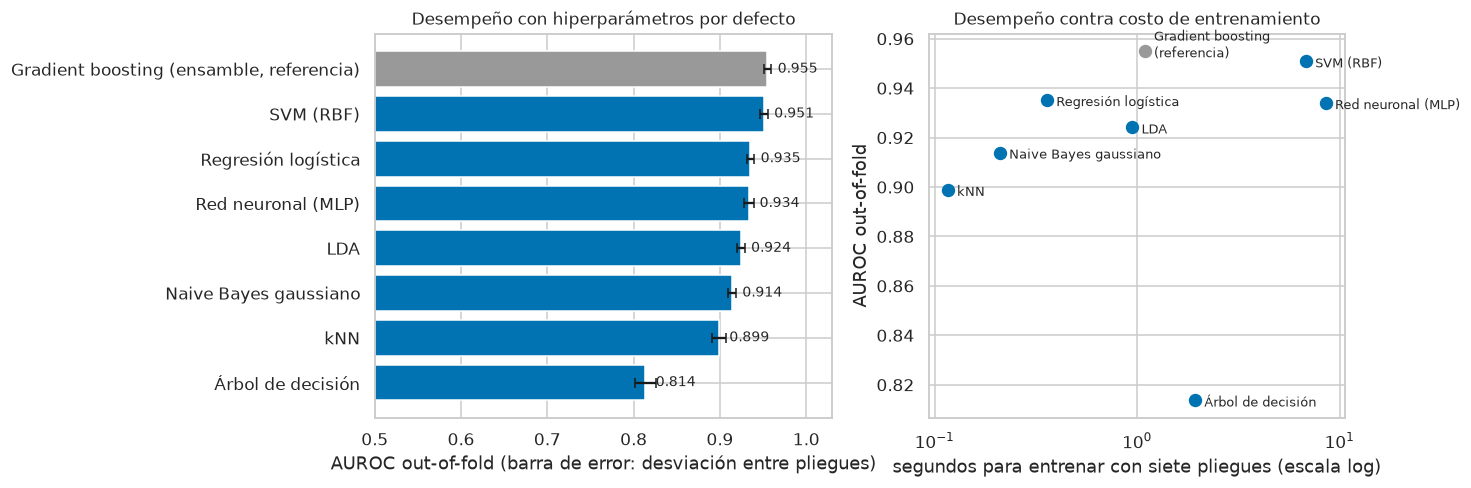

In [6]:
candidate_names = [n for n in default_table.index if n not in REFERENCE]
colors = {n: ("0.6" if n in REFERENCE else "C0") for n in default_table.index}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), width_ratios=[1.1, 1])
ax = axes[0]
ax.barh(default_table.index[::-1], default_table.AUROC[::-1], xerr=default_table.AUROC_desv_pliegues[::-1],
        color=[colors[n] for n in default_table.index[::-1]], capsize=3)
for i, value in enumerate(default_table.AUROC[::-1]):
    ax.text(value + 0.012, i, f"{value:.3f}", va="center", fontsize=9)
ax.set(xlim=(0.5, 1.03), xlabel="AUROC out-of-fold (barra de error: desviación entre pliegues)", title="Desempeño con hiperparámetros por defecto")
ax = axes[1]
for name, row in default_table.iterrows():
    ax.scatter(row.entrenamiento_s, row.AUROC, s=60, color=colors[name], zorder=3)
    ax.annotate(name.replace(" (ensamble, referencia)", "\n(referencia)"), (row.entrenamiento_s, row.AUROC), xytext=(6, -4), textcoords="offset points", fontsize=8.5)
ax.set(xscale="log", xlabel="segundos para entrenar con siete pliegues (escala log)", ylabel="AUROC out-of-fold", title="Desempeño contra costo de entrenamiento")
plt.tight_layout()
plt.show()

La SVM es el mejor modelo individual con sus valores por defecto. Tiene un AUROC de 0.951 y, derivando solo al 10% de los normales, detecta el 86.1% de las cardiopatías. Queda a 0.004 del gradient boosting de referencia (0.955), que es un ensamble.

Le siguen, muy juntas, la regresión logística (0.935) y la red neuronal (0.934). Después vienen LDA (0.924) y Naive Bayes (0.914). Los dos suponen algo sobre la forma de los datos: LDA, que cada clase es una nube normal con la misma covarianza, y Naive Bayes, que las características son independientes. Con 111 características correlacionadas, esos supuestos no se cumplen del todo.

kNN (0.899) y el árbol de decisión (0.814) quedan al final, en buena parte por sus valores por defecto. kNN vota con 5 vecinos, así que solo puede dar 6 puntuaciones distintas (de 0 a 5 votos). Con tan pocos niveles, para detectar al 95% de las cardiopatías tendría que derivar a todos: su especificidad con 95% de sensibilidad es 0. El árbol sin límite de profundidad memoriza el entrenamiento; en el Avance 3, limitado a profundidad 4, llegó a 0.880.

En costo, todos entrenan en segundos. La diferencia está al predecir: la SVM tarda más de 250 ms por cada 1,000 ECG, porque compara cada ECG nuevo con miles de ECG de entrenamiento. Los modelos lineales y la red neuronal tardan menos de 3 ms.

## 4. ¿Cuáles son los dos mejores?

Tomamos los dos primeros lugares por AUROC. Antes de cerrar la lista revisamos si el segundo lugar está claro: comparamos, pliegue por pliegue, el AUROC del segundo y del tercer lugar. Si el intervalo de 95% de esa diferencia incluye el cero, los dos modelos están empatados con estos datos y ajustamos a ambos, para no descartar a uno por ruido.

In [7]:
ranked = [n for n in default_table.index if n not in REFERENCE]


def fold_aurocs(name: str) -> np.ndarray:
    oof = default_runs[name]["oof"]
    return np.array([roc_auc_score(y_train[FOLD_TRAIN == f], oof[FOLD_TRAIN == f]) for f in np.unique(FOLD_TRAIN)])


tie_rows = []
for a, b in [(ranked[0], ranked[1]), (ranked[1], ranked[2])]:
    diff = fold_aurocs(a) - fold_aurocs(b)
    half_width = student_t.ppf(0.975, len(diff) - 1) * diff.std(ddof=1) / np.sqrt(len(diff))
    tie_rows.append({"comparación": f"{a} menos {b}", "diferencia_media": diff.mean(), "IC95_inf": diff.mean() - half_width,
                     "IC95_sup": diff.mean() + half_width, "pliegues_a_favor": f"{int((diff > 0).sum())} de {len(diff)}"})
ties = pd.DataFrame(tie_rows).set_index("comparación")
with pd.option_context("display.max_colwidth", None):
    display(ties.round(4))

TO_TUNE = ranked[:2] + ([ranked[2]] if ties.iloc[1].IC95_inf <= 0 else [])
print("Modelos que pasan al ajuste fino:", ", ".join(TO_TUNE))

,diferencia_media,IC95_inf,IC95_sup,pliegues_a_favor
comparación,,,,
SVM (RBF) menos Regresión logística,0.0156,0.0129,0.0182,8 de 8
Regresión logística menos Red neuronal (MLP),0.0013,-0.0030,0.0055,5 de 8


Modelos que pasan al ajuste fino: SVM (RBF), Regresión logística, Red neuronal (MLP)


La SVM gana con claridad: supera a la regresión logística en los 8 pliegues, por 0.016 en promedio, con un intervalo de [0.013, 0.018].

En cambio, la regresión logística y la red neuronal están empatadas. La diferencia es de 0.001, su intervalo [-0.003, 0.006] incluye el cero y la logística gana solo en 5 de los 8 pliegues. Por eso pasan tres modelos al ajuste fino: la SVM, la regresión logística y la red neuronal.

## 5. Ajuste fino de hiperparámetros

Para cada modelo hacemos una búsqueda aleatoria en dos etapas, siempre con los ocho pliegues de entrenamiento y el AUROC como criterio:

1. Búsqueda amplia: 60 configuraciones al azar dentro de rangos grandes. Los valores numéricos se sortean en escala logarítmica, porque importa el orden de magnitud (0.01, 0.1, 1, 10) más que el valor exacto.
2. Búsqueda alrededor del mejor: otras 30 configuraciones. Las opciones categóricas (por ejemplo, la arquitectura de la red) quedan fijas en las del mejor resultado, y los valores numéricos se buscan en un rango cuatro veces menor y cuatro veces mayor que el mejor.

Elegimos búsqueda aleatoria y no una malla completa porque, con el mismo número de entrenamientos, prueba más valores distintos de cada hiperparámetro. Cada configuración se entrena ocho veces, una por pliegue, así que cada modelo suma 720 entrenamientos.

Además del AUROC de validación cruzada guardamos el AUROC sobre los datos de entrenamiento, para vigilar que la mejor configuración no gane solo por memorizar.

In [8]:
def to_distributions(space: dict) -> dict:
    """Convierte la descripción del espacio en distribuciones que entiende RandomizedSearchCV."""
    kinds = {"log": lambda lo, hi: loguniform(lo, hi), "lin": lambda lo, hi: uniform(lo, hi - lo)}
    return {p: list(spec[1]) if spec[0] == "cat" else kinds[spec[0]](*spec[1:]) for p, spec in space.items()}


def narrow(space: dict, best: dict) -> dict:
    """Espacio de la segunda etapa: opciones categóricas fijas y rangos más estrechos alrededor del mejor valor."""
    narrowed = {}
    for p, spec in space.items():
        kind, value = spec[0], best[p]
        if kind == "cat":
            narrowed[p] = ("cat", [value])
        elif kind == "log":
            narrowed[p] = ("log", max(spec[1], value / 4), min(spec[2], value * 4))
        else:
            width = 0.15 * (spec[2] - spec[1])
            narrowed[p] = ("lin", max(spec[1], value - width), min(spec[2], value + width))
    return narrowed


def describe(config: dict) -> str:
    """Hiperparámetros en una línea legible."""
    return ", ".join(f"{k} = {v:.3g}" if isinstance(v, float) else f"{k} = {v}" for k, v in config.items())


def search(model, space: dict, n_iter: int, seed: int) -> pd.DataFrame:
    """Búsqueda aleatoria con los ocho pliegues de entrenamiento; devuelve una fila por configuración."""
    searcher = RandomizedSearchCV(model, to_distributions(space), n_iter=n_iter, scoring="roc_auc", cv=CV, refit=False,
                                  return_train_score=True, random_state=seed, n_jobs=N_JOBS, error_score="raise")
    searcher.fit(X_train, y_train)
    results = pd.DataFrame(searcher.cv_results_)
    params = pd.DataFrame(list(results.params))
    params = params.fillna({c: "None" for c in params.columns if not pd.api.types.is_numeric_dtype(params[c])})
    return pd.concat([params, results[["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"]]], axis=1).assign(
        configuracion=results.params)


def category_label(value) -> str:
    """Etiqueta corta para una opción categórica; las arquitecturas se escriben como 128-64."""
    return "-".join(map(str, value)) if isinstance(value, tuple) else str(value)


def show_search(results: pd.DataFrame, space: dict, title: str) -> None:
    """Una gráfica por hiperparámetro: AUROC de validación cruzada de cada configuración probada."""
    stages = {"1. amplia": "C0", "2. alrededor del mejor": "C1"}
    floor = results.mean_test_score.quantile(0.05)
    params = list(space)
    fig, axes = plt.subplots(1, len(params), figsize=(3.4 * len(params), 3.6), sharey=True)
    for ax, p in zip(np.atleast_1d(axes), params):
        kind = space[p][0]
        if kind == "cat":
            labels = results[p].map(category_label)
            sns.stripplot(x=labels, y=results.mean_test_score, hue=results.etapa, hue_order=list(stages), palette=stages,
                          order=[category_label(o) for o in space[p][1]], ax=ax, size=5, legend=False, jitter=0.25)
            ax.tick_params(axis="x", rotation=45)
        else:
            sns.scatterplot(x=results[p], y=results.mean_test_score, hue=results.etapa, hue_order=list(stages), palette=stages, ax=ax, s=28, legend=False)
            if kind == "log":
                ax.set_xscale("log")
                ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set(xlabel=p, ylabel="AUROC (validación cruzada)", ylim=(floor - 0.002, results.mean_test_score.max() + 0.002))
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=s) for s, c in stages.items()]
    fig.legend(handles=handles, title="etapa de la búsqueda", loc="upper right", bbox_to_anchor=(1.0, 1.12), ncols=2, frameon=False)
    fig.suptitle(title, fontsize=11, x=0.02, y=1.08, ha="left")
    plt.tight_layout()
    plt.show()
    hidden = results[results.mean_test_score < floor - 0.002]
    if len(hidden):
        print(f"Para que se vean las diferencias, el eje empieza en {floor - 0.002:.3f}. Quedan fuera {len(hidden)} configuraciones, "
              f"la peor con AUROC de {hidden.mean_test_score.min():.3f}.")

In [9]:
SPACES = {
    "SVM (RBF)": (SVC(cache_size=1000), {
        "C": ("log", 0.01, 100),
        "gamma": ("log", 1e-4, 0.1),
        "class_weight": ("cat", [None, "balanced"]),
    }),
    "Regresión logística": (LogisticRegression(solver="saga", max_iter=5000), {
        "C": ("log", 1e-3, 100),
        "l1_ratio": ("lin", 0, 1),
        "class_weight": ("cat", [None, "balanced"]),
    }),
    "Red neuronal (MLP)": (MLPClassifier(early_stopping=True, n_iter_no_change=15, max_iter=500, random_state=SEED), {
        "hidden_layer_sizes": ("cat", [(32,), (64,), (128,), (256,), (64, 32), (128, 64), (256, 128), (128, 64, 32), (256, 128, 64)]),
        "activation": ("cat", ["relu", "tanh", "logistic"]),
        "alpha": ("log", 1e-5, 10),
        "learning_rate_init": ("log", 1e-4, 1e-2),
        "batch_size": ("cat", [64, 128, 256, 512]),
    }),
}
N_WIDE, N_NEAR = 60, 30
searches, TUNED = {}, {}


def tune(name: str) -> pd.DataFrame:
    """Las dos etapas de búsqueda de un modelo; guarda la mejor configuración en TUNED."""
    model, space = SPACES[name]
    start = time.perf_counter()
    wide = search(model, space, N_WIDE, SEED).assign(etapa="1. amplia")
    best_wide = wide.loc[wide.mean_test_score.idxmax(), "configuracion"]
    near = search(model, narrow(space, best_wide), N_NEAR, SEED + 1).assign(etapa="2. alrededor del mejor")
    results = pd.concat([wide, near], ignore_index=True).sort_values("mean_test_score", ascending=False, ignore_index=True)
    results["brecha_train_cv"] = results.mean_train_score - results.mean_test_score
    TUNED[name] = clone(model).set_params(**results.configuracion[0])
    searches[name] = results
    default_auroc = fold_aurocs(name).mean()
    print(f"{len(results)} configuraciones x 8 pliegues en {(time.perf_counter() - start) / 60:.1f} min")
    print(f"Mejor configuración: {describe(results.configuracion[0])}")
    print(f"AUROC medio por pliegue: por defecto {default_auroc:.4f} | mejor de la etapa 1 {wide.mean_test_score.max():.4f} | "
          f"mejor de la etapa 2 {near.mean_test_score.max():.4f}")
    shown = results.head(5).drop(columns=["configuracion"]).rename(columns={"mean_test_score": "AUROC_cv", "std_test_score": "desv_cv",
                                                                             "mean_train_score": "AUROC_train", "mean_fit_time": "segundos_por_ajuste"})
    display(shown.round(4))
    return results

### 5.1 SVM con kernel RBF

La SVM con kernel RBF tiene dos hiperparámetros principales, y los dos controlan qué tan flexible es la frontera:

| Hiperparámetro | Qué controla | Rango |
| --- | --- | --- |
| `C` | Cuánto castiga los errores de entrenamiento. Con `C` grande la frontera se dobla para acertar cada ECG; con `C` pequeño acepta errores a cambio de una frontera más suave. | 0.01 a 100 |
| `gamma` | El alcance de cada ECG de entrenamiento. Con `gamma` grande cada punto solo influye en su vecindad inmediata y la frontera se vuelve muy irregular. | 0.0001 a 0.1 (el valor por defecto con estos datos es 0.010) |
| `class_weight` | Si se da más peso a la clase minoritaria (normales). | sin peso o balanceado |

90 configuraciones x 8 pliegues en 20.1 min
Mejor configuración: C = 2.61, class_weight = None, gamma = 0.00625
AUROC medio por pliegue: por defecto 0.9509 | mejor de la etapa 1 0.9508 | mejor de la etapa 2 0.9511


,C,class_weight,gamma,AUROC_cv,desv_cv,AUROC_train,segundos_por_ajuste,etapa,brecha_train_cv
0,2.6102,None,0.0063,0.9511,0.0044,0.9707,9.3709,2. alrededor del mejor,0.0196
1,2.8374,None,0.0060,0.9511,0.0044,0.9708,6.3846,2. alrededor del mejor,0.0197
2,1.1175,None,0.0106,0.9510,0.0044,0.9718,8.7590,2. alrededor del mejor,0.0208
3,1.7722,None,0.0102,0.9510,0.0045,0.9768,7.8017,2. alrededor del mejor,0.0259
4,0.9445,None,0.0136,0.9508,0.0045,0.9747,9.1288,1. amplia,0.0239


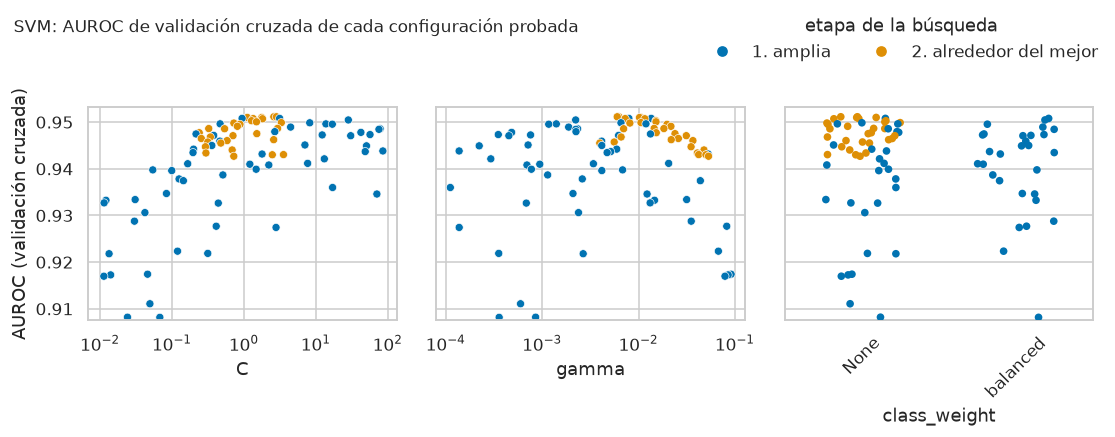

Para que se vean las diferencias, el eje empieza en 0.907. Quedan fuera 3 configuraciones, la peor con AUROC de 0.892.


In [10]:
svm_search = tune("SVM (RBF)")
show_search(svm_search, SPACES["SVM (RBF)"][1], "SVM: AUROC de validación cruzada de cada configuración probada")

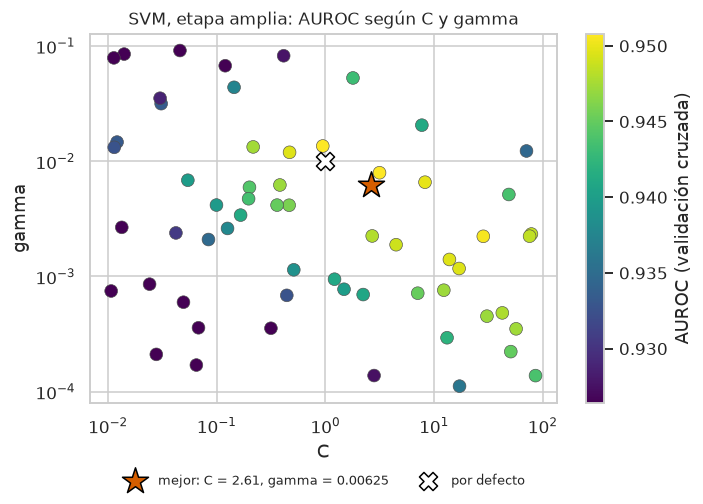

In [11]:
wide = svm_search[svm_search.etapa == "1. amplia"]
fig, ax = plt.subplots(figsize=(6.6, 4.8))
points = ax.scatter(wide.C, wide.gamma, c=wide.mean_test_score, cmap="viridis", s=70, vmin=wide.mean_test_score.quantile(0.2), edgecolor="0.3", linewidth=0.4)
best = svm_search.iloc[0]
ax.scatter(best.C, best.gamma, marker="*", s=320, color="C3", edgecolor="black", label=f"mejor: C = {best.C:.3g}, gamma = {best.gamma:.3g}")
ax.scatter(1.0, 1 / (len(FEATURES) * X_train.to_numpy().var()), marker="X", s=140, color="white", edgecolor="black", label="por defecto")
ax.set(xscale="log", yscale="log", xlabel="C", ylabel="gamma", title="SVM, etapa amplia: AUROC según C y gamma")
fig.colorbar(points, ax=ax, label="AUROC (validación cruzada)")
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

La búsqueda confirma que la SVM ya estaba bien configurada. La mejor configuración (`C = 2.61`, `gamma = 0.0063`) obtiene 0.9511 de AUROC medio por pliegue, contra 0.9509 con los valores por defecto. La diferencia, 0.0002, es mucho menor que la variación entre pliegues (0.0044).

La gráfica de `C` contra `gamma` explica por qué. Las buenas configuraciones forman una franja diagonal: un `C` mayor se compensa con un `gamma` menor, y el valor por defecto cae dentro de esa franja. Fuera de ella el AUROC baja. Con `C` menor de 0.1 ninguna configuración pasa de 0.940, y las tres peores (hasta 0.892) combinan `C` y `gamma` pequeños: la frontera es demasiado rígida. Con `gamma` mayor de 0.03 el AUROC queda entre 0.917 y 0.947, porque la frontera se vuelve demasiado irregular.

Dar más peso a la clase minoritaria no ayudó: el mejor resultado con pesos balanceados (0.9508) es prácticamente igual al mejor sin ellos (0.9511). La brecha entre entrenamiento y validación cruzada de la mejor es de 0.020: la SVM se ajusta más al entrenamiento que la regresión logística, pero aun así generaliza mejor.

### 5.2 Regresión logística

En el Avance 3 solo ajustamos `C` con penalización L2. Aquí ampliamos el espacio con el tipo de penalización:

| Hiperparámetro | Qué controla | Rango |
| --- | --- | --- |
| `C` | Inverso de la fuerza de la regularización. | 0.001 a 100 |
| `l1_ratio` | Mezcla de penalizaciones (elastic net). 0 es L2, que encoge todos los coeficientes; 1 es L1, que lleva a cero los que no aportan. | 0 a 1 |
| `class_weight` | Si se da más peso a la clase minoritaria. | sin peso o balanceado |

Usamos el optimizador `saga`, el que acepta cualquier mezcla de L1 y L2.

90 configuraciones x 8 pliegues en 4.1 min
Mejor configuración: C = 1.28, class_weight = None, l1_ratio = 0.89
AUROC medio por pliegue: por defecto 0.9353 | mejor de la etapa 1 0.9365 | mejor de la etapa 2 0.9365


,C,class_weight,l1_ratio,AUROC_cv,desv_cv,AUROC_train,segundos_por_ajuste,etapa,brecha_train_cv
0,1.2762,None,0.8901,0.9365,0.0041,0.9402,6.2577,2. alrededor del mejor,0.0037
1,1.2557,None,0.8739,0.9365,0.0041,0.9402,6.2838,2. alrededor del mejor,0.0037
2,1.1003,None,0.8411,0.9365,0.0041,0.9402,6.6882,2. alrededor del mejor,0.0037
3,1.0298,None,0.7839,0.9365,0.0041,0.9402,6.5765,2. alrededor del mejor,0.0036
4,1.3968,None,0.8037,0.9365,0.0041,0.9402,5.7251,2. alrededor del mejor,0.0037


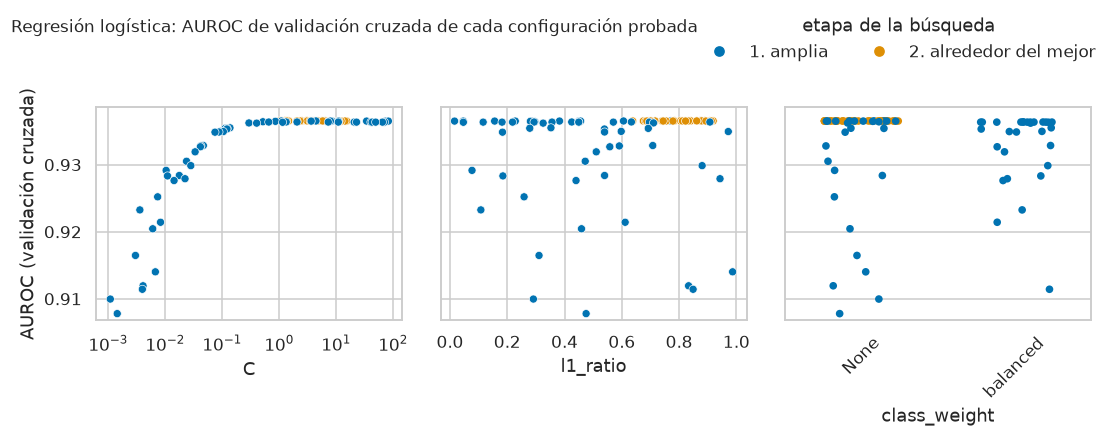

Para que se vean las diferencias, el eje empieza en 0.907. Quedan fuera 4 configuraciones, la peor con AUROC de 0.896.


In [12]:
logistic_search = tune("Regresión logística")
show_search(logistic_search, SPACES["Regresión logística"][1], "Regresión logística: AUROC de validación cruzada de cada configuración probada")

La regresión logística apenas cambia. La mejor configuración (`C = 1.28`, con una mezcla de 89% L1) llega a 0.9365, contra 0.9353 del baseline del Avance 3: 0.0012 más.

La gráfica muestra una meseta. Con `C` menor de 0.01 el AUROC baja hasta 0.896, pero a partir de `C = 0.3` todas las configuraciones quedan entre 0.9362 y 0.9365. Dentro de esa meseta, ni el tipo de penalización ni el peso de las clases mueven el resultado. Es el mismo límite que encontró el Avance 3: una frontera lineal ya aprovechó lo que podía de estas características.

### 5.3 Red neuronal (MLP)

En la red neuronal hay más decisiones, porque además de la regularización se elige la forma de la red y cómo se entrena:

| Hiperparámetro | Qué controla | Opciones |
| --- | --- | --- |
| `hidden_layer_sizes` | La arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. | de una capa de 32 neuronas a tres capas de 256, 128 y 64 |
| `activation` | La función de activación de las neuronas ocultas. | ReLU, tangente hiperbólica o logística |
| `alpha` | Regularización L2 de los pesos. | 0.00001 a 10 |
| `learning_rate_init` | Tasa de aprendizaje inicial del optimizador Adam. | 0.0001 a 0.01 |
| `batch_size` | Cuántos ECG se usan en cada actualización de los pesos. | 64, 128, 256 o 512 |

A diferencia de la versión por defecto, todas las configuraciones usan parada temprana (`early_stopping`): la red aparta el 10% de sus datos de entrenamiento y deja de entrenar cuando el desempeño en ese 10% no mejora durante 15 épocas. Es otra defensa contra el sobreajuste.

90 configuraciones x 8 pliegues en 3.0 min
Mejor configuración: activation = relu, alpha = 0.13, batch_size = 64, hidden_layer_sizes = (64,), learning_rate_init = 0.000315
AUROC medio por pliegue: por defecto 0.9340 | mejor de la etapa 1 0.9491 | mejor de la etapa 2 0.9492


,activation,alpha,batch_size,hidden_layer_sizes,learning_rate_init,AUROC_cv,desv_cv,AUROC_train,segundos_por_ajuste,etapa,brecha_train_cv
0,relu,0.1297,64,"(64,)",0.0003,0.9492,0.0035,0.9664,2.5644,2. alrededor del mejor,0.0172
1,relu,0.1534,64,"(64,)",0.0004,0.9492,0.0036,0.9670,2.3030,2. alrededor del mejor,0.0179
2,relu,0.0957,64,"(64,)",0.0002,0.9491,0.0036,0.9655,2.8578,1. amplia,0.0164
3,relu,0.0895,64,"(64,)",0.0004,0.9489,0.0038,0.9657,1.9039,2. alrededor del mejor,0.0167
4,relu,0.1517,64,"(64,)",0.0003,0.9489,0.0036,0.9649,2.4270,2. alrededor del mejor,0.0160


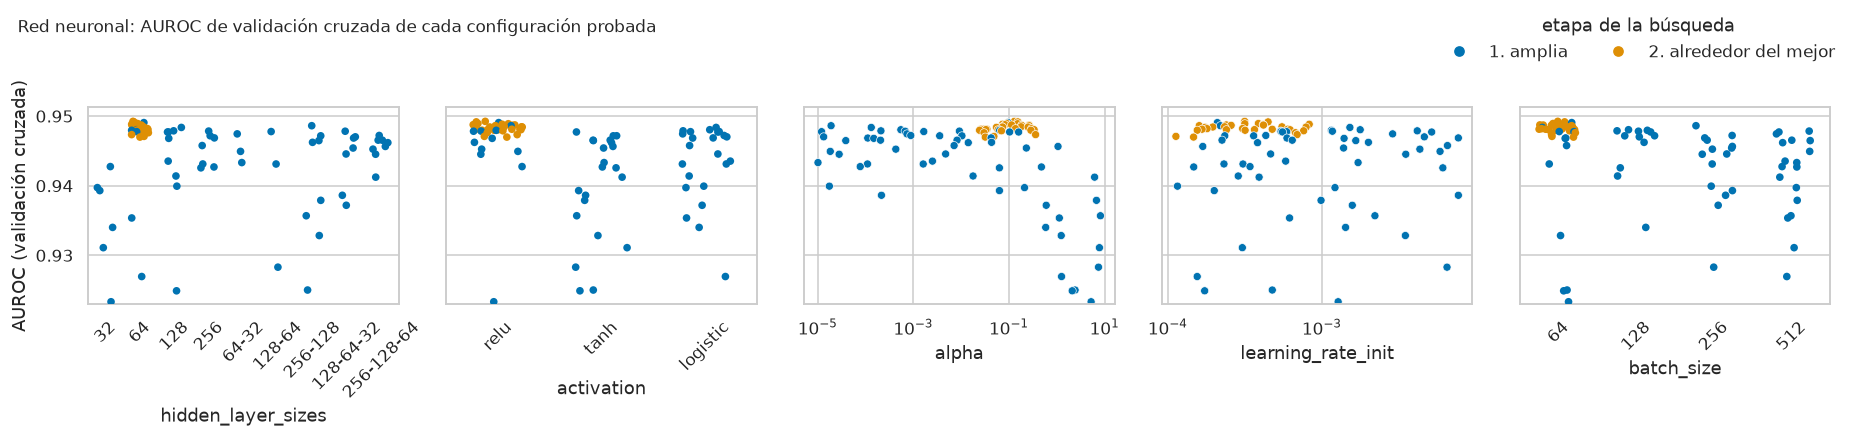

Para que se vean las diferencias, el eje empieza en 0.923. Quedan fuera 3 configuraciones, la peor con AUROC de 0.484.


In [13]:
mlp_search = tune("Red neuronal (MLP)")
show_search(mlp_search, SPACES["Red neuronal (MLP)"][1], "Red neuronal: AUROC de validación cruzada de cada configuración probada")

In [14]:
mlp_wide = mlp_search[mlp_search.etapa == "1. amplia"].assign(arquitectura=lambda d: d.hidden_layer_sizes.map(category_label))
summary_by = {p: mlp_wide.groupby(p).mean_test_score.agg(["max", "median", "size"]).rename(columns={"max": "mejor_AUROC", "median": "mediana_AUROC", "size": "configuraciones"})
              for p in ["arquitectura", "activation"]}
for p, table in summary_by.items():
    display(table.sort_values("mejor_AUROC", ascending=False).round(4))

,mejor_AUROC,mediana_AUROC,configuraciones
arquitectura,,,
64,0.9491,0.9478,7
256-128,0.9486,0.9421,8
128,0.9484,0.9468,9
256,0.9478,0.9444,8
128-64-32,0.9478,0.9450,8
128-64,0.9478,0.9431,3
64-32,0.9474,0.9449,3
256-128-64,0.9472,0.9459,8
32,0.9427,0.9366,6


,mejor_AUROC,mediana_AUROC,configuraciones
activation,,,
relu,0.9491,0.9462,13
logistic,0.9484,0.9446,25
tanh,0.9477,0.9426,22


La red neuronal es la que más gana con el ajuste. Pasa de 0.9340 a 0.9492 de AUROC medio por pliegue, 0.015 más. La mejor configuración es sencilla: una sola capa oculta de 64 neuronas con activación ReLU, `alpha = 0.13`, tasa de aprendizaje de 0.0003 y lotes de 64 ECG.

Lo que muestran las gráficas y las tablas:

- Casi cualquier configuración razonable supera a la red por defecto (0.934). En la etapa amplia lo hacen 50 de las 60, y entre las que tienen `alpha` menor de 1, 45 de 46. Todas comparten la parada temprana, que la versión por defecto no usa.
- Lo que más daña a la red es regularizarla de más. En la etapa amplia, con `alpha` hasta 0.3 la mediana del AUROC ronda 0.946 y ahí está el mejor resultado (0.949). Con `alpha` mayor de 1 la mediana baja a 0.930, porque la red queda demasiado restringida.
- La arquitectura importa poco. En la etapa amplia, la mejor red de cada arquitectura queda entre 0.947 y 0.949, salvo la de una capa de 32 neuronas (0.943). Agregar capas no ayudó.
- La activación también importa poco. ReLU dio el mejor resultado (0.949), pero la logística (0.948) y la tangente hiperbólica (0.948) quedan muy cerca.
- Tres configuraciones quedan fuera de la gráfica. La peor, con activación logística, `alpha = 0.78` y la tasa de aprendizaje más alta de las tres (0.0029), no aprendió nada: su AUROC de 0.484 es el del azar, tanto en entrenamiento como en validación. Las otras dos tienen `alpha` mayor de 5.

La brecha entre entrenamiento y validación cruzada de la mejor red es de 0.017, parecida a la de la SVM.

## 6. Antes y después del ajuste

Ahora comparamos cada modelo con sus hiperparámetros por defecto y ya ajustado. Lo hacemos en dos lugares:

- La validación cruzada, que es donde se hizo la búsqueda. Aquí la mejora puede estar un poco inflada, porque elegimos la mejor de 90 configuraciones con estos mismos pliegues.
- El pliegue 9 de validación, que ninguna búsqueda vio. Es la comparación honesta.

Para el costo medimos el tiempo de entrenar con los 17,083 ECG de entrenamiento y el de puntuar 1,000 ECG.

In [15]:
BASELINE = "Regresión logística"
BASELINE_LABEL = f"{BASELINE} (Avance 3)"
versions = {BASELINE_LABEL: CANDIDATES[BASELINE]}
for name in TO_TUNE:
    if name != BASELINE:
        versions[f"{name}, por defecto"] = CANDIDATES[name]
    versions[f"{name}, ajustado"] = TUNED[name]

final_runs, fitted, val_score = {}, {}, {}
for label, model in versions.items():
    final_runs[label] = default_runs[BASELINE] if label == BASELINE_LABEL else cross_validate_model(model)
    start = time.perf_counter()
    fitted[label] = clone(model).fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    val_score[label] = model_score(fitted[label], X[val])
    final_runs[label] = {**final_runs[label], "entrenamiento_completo_s": fit_seconds,
                         "prediccion_val_ms_por_1000": 1000 * (time.perf_counter() - start) / val.sum() * 1000}

COLUMNS = ["AUROC", "sens_con_esp_90", "esp_con_sens_95"]
before_after = pd.concat({
    "validación cruzada": pd.DataFrame({k: summarize(y_train, r["oof"]) for k, r in final_runs.items()}).T[COLUMNS],
    "validación (pliegue 9)": pd.DataFrame({k: summarize(y[val], s) for k, s in val_score.items()}).T[COLUMNS],
    "costo": pd.DataFrame({k: {"entrenamiento_s": r["entrenamiento_completo_s"], "prediccion_ms_por_1000": r["prediccion_val_ms_por_1000"]}
                           for k, r in final_runs.items()}).T,
}, axis=1)
display(before_after.round(3))

validación cruzada                  \
                                             AUROC sens_con_esp_90   
Regresión logística (Avance 3)               0.935           0.826   
SVM (RBF), por defecto                       0.951           0.861   
SVM (RBF), ajustado                          0.951           0.864   
Regresión logística, ajustado                0.936           0.827   
Red neuronal (MLP), por defecto              0.934           0.822   
Red neuronal (MLP), ajustado                 0.949           0.857   

                                                validación (pliegue 9)  \
                                esp_con_sens_95                  AUROC   
Regresión logística (Avance 3)            0.620                  0.928   
SVM (RBF), por defecto                    0.712                  0.940   
SVM (RBF), ajustado                       0.709                  0.939   
Regresión logística, ajustado             0.624                  0.929   
Red neuronal (MLP), por defecto           0.602                  0.910   
Red neuronal (MLP), ajustado              0.693                  0.939   

                                                                 \
                                sens_con_esp_90 esp_con_sens_95   
Regresión logística (Avance 3)            0.804           0.566   
SVM (RBF), por defecto                    0.826           0.675   
SVM (RBF), ajustado                       0.832           0.656   
Regresión logística, ajustado             0.810           0.560   
Red neuronal (MLP), por defecto           0.758           0.536   
Red neuronal (MLP), ajustado              0.828           0.652   

                                          costo                         
                                entrenamiento_s prediccion_ms_por_1000  
Regresión logística (Avance 3)            0.177                  1.709  
SVM (RBF), por defecto                    4.429                326.200  
SVM (RBF), ajustado                       4.140                293.477  
Regresión logística, ajustado             6.229                  1.774  
Red neuronal (MLP), por defecto           7.583                  2.184  
Red neuronal (MLP), ajustado              2.903                  1.828

In [16]:
y_val, patients_val = y[val].to_numpy(), patients[val.to_numpy()]
tuned_labels = [f"{n}, ajustado" for n in TO_TUNE]
pairs = [(f"{n}, ajustado", BASELINE_LABEL if n == BASELINE else f"{n}, por defecto") for n in TO_TUNE]
pairs += [(a, b) for i, a in enumerate(tuned_labels) for b in tuned_labels[i + 1:]]
difference_rows = []
for a, b in pairs:
    d = paired_auroc_difference(patients_val, y_val, val_score[a], val_score[b])
    difference_rows.append({"comparación": f"{a} menos {b}", "diferencia_AUROC": d["difference"], "IC95_inf": d["ci_low"], "IC95_sup": d["ci_high"]})
differences = pd.DataFrame(difference_rows).set_index("comparación")
print("Diferencias de AUROC en el pliegue 9, con intervalo de 95% por bootstrap de pacientes (2,000 repeticiones):")
with pd.option_context("display.max_colwidth", None):
    display(differences.round(4))

Diferencias de AUROC en el pliegue 9, con intervalo de 95% por bootstrap de pacientes (2,000 repeticiones):


,diferencia_AUROC,IC95_inf,IC95_sup
comparación,,,
"SVM (RBF), ajustado menos SVM (RBF), por defecto",-0.0007,-0.0017,0.0003
"Regresión logística, ajustado menos Regresión logística (Avance 3)",0.0008,-0.0006,0.0023
"Red neuronal (MLP), ajustado menos Red neuronal (MLP), por defecto",0.0294,0.0223,0.0367
"SVM (RBF), ajustado menos Regresión logística, ajustado",0.0104,0.0043,0.0168
"SVM (RBF), ajustado menos Red neuronal (MLP), ajustado",-0.0003,-0.0031,0.0027
"Regresión logística, ajustado menos Red neuronal (MLP), ajustado",-0.0106,-0.0161,-0.0053


El pliegue 9, que ninguna búsqueda vio, confirma lo que dijo la validación cruzada:

- La red neuronal mejora de verdad. Su AUROC sube de 0.910 a 0.939, una ganancia de 0.029 con intervalo [0.022, 0.037]. También mejora en los dos puntos de operación: con 10% de normales derivados detecta el 82.8% de las cardiopatías (antes 75.8%), y con 95% de sensibilidad deja sin derivar al 65.2% de los normales (antes 53.6%).
- La SVM y la regresión logística no cambian. Sus diferencias contra la versión anterior (-0.0007 y +0.0008) tienen intervalos que incluyen el cero.
- La SVM y la red neuronal ajustadas quedan empatadas: la diferencia es de -0.0003, con intervalo [-0.0031, 0.0027]. Las dos superan a la regresión logística ajustada por 0.010, con intervalos que no incluyen el cero.

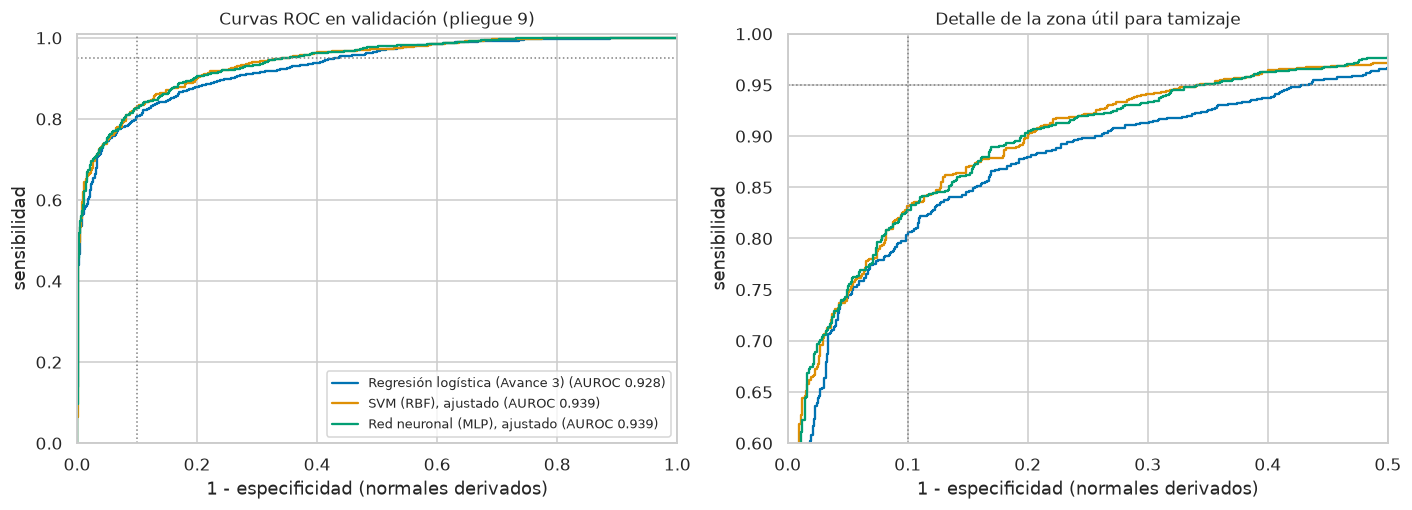

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
roc_labels = [BASELINE_LABEL] + [label for label in tuned_labels if not label.startswith(BASELINE)]
for ax, (xlim, ylim) in zip(axes, [((0, 1), (0, 1.01)), ((0, 0.5), (0.6, 1.0))]):
    for label in roc_labels:
        fpr, tpr, _ = roc_curve(y_val, val_score[label])
        ax.plot(fpr, tpr, label=f"{label} (AUROC {roc_auc_score(y_val, val_score[label]):.3f})")
    ax.axvline(0.10, color="0.5", linestyle=":", linewidth=1)
    ax.axhline(0.95, color="0.5", linestyle=":", linewidth=1)
    ax.set(xlim=xlim, ylim=ylim, xlabel="1 - especificidad (normales derivados)", ylabel="sensibilidad")
axes[0].set_title("Curvas ROC en validación (pliegue 9)")
axes[1].set_title("Detalle de la zona útil para tamizaje")
axes[0].legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()

Las curvas ROC cuentan lo mismo. En la zona útil para tamizaje, con pocos normales derivados, la SVM y la red neuronal casi se enciman, y las dos quedan por encima de la regresión logística.

## 7. Elección del modelo individual final

La métrica principal no es lo único que importa para un tamizaje. Reunimos en una tabla lo que pesa en la decisión: desempeño en datos no vistos, costo, tamaño del modelo, si entrega probabilidades y qué tan fácil es explicarlo. Después revisamos si la red neuronal depende de la semilla aleatoria.

In [18]:
def model_size(model) -> str:
    """Cuántos números guarda el modelo para decidir."""
    if isinstance(model, SVC):
        return f"{model.support_vectors_.shape[0]:,} vectores de soporte x {model.support_vectors_.shape[1]}"
    if isinstance(model, MLPClassifier):
        return f"{sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_):,} pesos"
    return f"{model.coef_.size + 1} coeficientes"


QUALITATIVE = {
    "SVM (RBF)": {"probabilidades": "no; da una distancia a la frontera", "interpretabilidad": "baja; la decisión depende de miles de ECG de referencia"},
    "Regresión logística": {"probabilidades": "sí", "interpretabilidad": "alta; un coeficiente por característica"},
    "Red neuronal (MLP)": {"probabilidades": "sí", "interpretabilidad": "baja; pesos sin significado clínico directo"},
}
decision = pd.DataFrame({name: {
    "AUROC_cv": summarize(y_train, final_runs[f"{name}, ajustado"]["oof"])["AUROC"],
    "AUROC_val": summarize(y_val, val_score[f"{name}, ajustado"])["AUROC"],
    "sens_con_esp_90_val": summarize(y_val, val_score[f"{name}, ajustado"])["sens_con_esp_90"],
    "esp_con_sens_95_val": summarize(y_val, val_score[f"{name}, ajustado"])["esp_con_sens_95"],
    "entrenamiento_s": final_runs[f"{name}, ajustado"]["entrenamiento_completo_s"],
    "prediccion_ms_por_1000": final_runs[f"{name}, ajustado"]["prediccion_val_ms_por_1000"],
    "tamaño": model_size(fitted[f"{name}, ajustado"]),
    **QUALITATIVE[name],
} for name in TO_TUNE}).T
with pd.option_context("display.max_colwidth", None, "display.float_format", "{:.3f}".format):
    display(decision)
print("Hiperparámetros elegidos:")
for name in TO_TUNE:
    print(f"  {name}: {describe(searches[name].configuracion[0])}")

,AUROC_cv,AUROC_val,sens_con_esp_90_val,esp_con_sens_95_val,entrenamiento_s,prediccion_ms_por_1000,tamaño,probabilidades,interpretabilidad
SVM (RBF),0.951,0.939,0.832,0.656,4.140,293.477,"5,482 vectores de soporte x 111",no; da una distancia a la frontera,baja; la decisión depende de miles de ECG de referencia
Regresión logística,0.936,0.929,0.810,0.560,6.229,1.774,112 coeficientes,sí,alta; un coeficiente por característica
Red neuronal (MLP),0.949,0.939,0.828,0.652,2.903,1.828,"7,233 pesos",sí,baja; pesos sin significado clínico directo


Hiperparámetros elegidos:
  SVM (RBF): C = 2.61, class_weight = None, gamma = 0.00625
  Regresión logística: C = 1.28, class_weight = None, l1_ratio = 0.89
  Red neuronal (MLP): activation = relu, alpha = 0.13, batch_size = 64, hidden_layer_sizes = (64,), learning_rate_init = 0.000315


### ¿La red neuronal depende de la semilla?

La SVM y la regresión logística resuelven un problema de optimización con una sola solución: si se entrenan dos veces con los mismos datos, dan el mismo modelo. La red neuronal no. Sus pesos iniciales se sortean, y una semilla distinta puede llevar a otro resultado. Antes de elegir, entrenamos la red ajustada con cinco semillas diferentes.

In [19]:
MLP_NAME = "Red neuronal (MLP)"
seed_rows = []
for seed in range(5):
    model = clone(TUNED[MLP_NAME]).set_params(random_state=seed)
    run = cross_validate_model(model)
    model.fit(X_train, y_train)
    seed_rows.append({"semilla": seed, "AUROC_validación_cruzada": roc_auc_score(y_train, run["oof"]),
                      "AUROC_validación (pliegue 9)": roc_auc_score(y_val, model_score(model, X[val]))})
seeds = pd.DataFrame(seed_rows).set_index("semilla")
display(seeds.round(4))
spread = seeds.max() - seeds.min()
print(f"Diferencia entre la mejor y la peor semilla: {spread.iloc[0]:.4f} en validación cruzada y {spread.iloc[1]:.4f} en el pliegue 9")

,AUROC_validación_cruzada,AUROC_validación (pliegue 9)
semilla,,
0,0.9493,0.9395
1,0.9492,0.9374
2,0.9483,0.9396
3,0.9479,0.9393
4,0.9483,0.9364


Diferencia entre la mejor y la peor semilla: 0.0014 en validación cruzada y 0.0033 en el pliegue 9


La red es estable. Entre la mejor y la peor de las cinco semillas hay 0.0014 de AUROC en validación cruzada y 0.0033 en el pliegue 9. Es una variación pequeña frente a la ventaja de la red sobre el baseline en ese mismo pliegue (0.011).

Elegimos la red neuronal ajustada como modelo individual final.

La SVM y la red discriminan igual: las dos tienen 0.939 de AUROC en el pliegue 9, la diferencia entre ellas es de -0.0003 [-0.0031, 0.0027] y sus puntos de operación son casi idénticos. Como la métrica principal no las separa, decidimos por lo demás:

| Criterio | SVM | Red neuronal |
| --- | --- | --- |
| AUROC en validación (pliegue 9) | 0.939 | 0.939 |
| Lo que guarda el modelo | 5,482 ECG de entrenamiento (vectores de soporte) | 7,233 pesos |
| Tiempo para puntuar 1,000 ECG | más de 250 ms | unos 2 ms |
| Probabilidades | No. Da una distancia a la frontera, y obtener probabilidades requiere un paso extra de calibración. | Sí |
| Estabilidad | Siempre da el mismo modelo. | Varía 0.003 de AUROC según la semilla. |
| Interpretabilidad | Baja | Baja |

Lo que más pesa es lo que guarda cada modelo. La SVM decide comparando cada ECG nuevo con 5,482 ECG de entrenamiento, así que el archivo del modelo contiene esos registros. Cuando el modelo se entrene con datos de estudiantes, eso significaría guardar y mover información de salud de personas reales junto con el modelo. La red neuronal solo guarda pesos.

La red además entrega probabilidades, que son más fáciles de explicar y de calibrar que una distancia. La velocidad no decide: en un tamizaje de unos cientos de estudiantes los dos modelos responden en menos de un segundo. El costo de la red es su dependencia de la semilla, que medimos y es pequeña.

Lo que perdemos es interpretabilidad. Si el cardiólogo necesita ver por qué se derivó a cada estudiante, la regresión logística sigue siendo la alternativa: pierde 0.010 de AUROC en el pliegue 9, pero cada coeficiente se puede leer.

In [20]:
FINAL_NAME = "Red neuronal (MLP)"
FINAL_LABEL = f"{FINAL_NAME}, ajustado"
print(f"Modelo individual final: {FINAL_NAME}, con {describe(searches[FINAL_NAME].configuracion[0])}")

Modelo individual final: Red neuronal (MLP), con activation = relu, alpha = 0.13, batch_size = 64, hidden_layer_sizes = (64,), learning_rate_init = 0.000315


### Verificación única en el pliegue de prueba

Con la elección ya tomada, evaluamos una sola vez en el pliegue 10 el modelo final y el baseline del Avance 3. Este pliegue ya se usó al final del Avance 3; aquí se usa de nuevo solo para el modelo elegido, sin cambiar nada después de verlo. El umbral del punto de operación se fija como en el Avance 3: con las predicciones out-of-fold de entrenamiento, en el valor que deriva al 10% de los ECG normales. Los intervalos de 95% vienen de remuestrear pacientes completos.

In [21]:
y_test, patients_test = y[test].to_numpy(), patients[test.to_numpy()]
TEST_MODELS = [BASELINE_LABEL, FINAL_LABEL]
test_score = {label: model_score(fitted[label], X[test]) for label in TEST_MODELS}
THRESHOLDS = {label: float(np.quantile(final_runs[label]["oof"][(y_train == 0).to_numpy()], 0.90)) for label in TEST_MODELS}

test_rows = []
for label in TEST_MODELS:
    m = metric_intervals(y_test, test_score[label], patients_test, THRESHOLDS[label])["metrics"]
    interval = lambda k: f"{m[k]['value']:.3f} [{m[k]['ci_low']:.3f}, {m[k]['ci_high']:.3f}]"
    test_rows.append({"modelo": label, "AUROC": interval("auroc"), "sensibilidad (umbral del 10%)": interval("sensitivity"),
                      "especificidad (umbral del 10%)": interval("specificity"), "esp_con_sens_95": f"{specificity_at_sensitivity(y_test, test_score[label]):.3f}",
                      "AUPRC": interval("average_precision")})
display(pd.DataFrame(test_rows).set_index("modelo"))
gain = paired_auroc_difference(patients_test, y_test, test_score[FINAL_LABEL], test_score[BASELINE_LABEL])
print(f"AUROC del modelo final menos el baseline, en prueba: {gain['difference']:+.4f}, IC 95% [{gain['ci_low']:+.4f}, {gain['ci_high']:+.4f}]")

,AUROC,sensibilidad (umbral del 10%),especificidad (umbral del 10%),esp_con_sens_95,AUPRC
modelo,,,,,
Regresión logística (Avance 3),"0.917 [0.905, 0.929]","0.772 [0.748, 0.797]","0.907 [0.887, 0.925]",0.536,"0.946 [0.937, 0.955]"
"Red neuronal (MLP), ajustado","0.933 [0.923, 0.943]","0.801 [0.778, 0.825]","0.909 [0.890, 0.927]",0.596,"0.956 [0.948, 0.964]"


AUROC del modelo final menos el baseline, en prueba: +0.0158, IC 95% [+0.0101, +0.0218]


La red neuronal confirma su ventaja en datos nuevos. En el pliegue 10 su AUROC es 0.933 [0.923, 0.943], contra 0.917 del baseline: una ganancia de 0.016, con intervalo [0.010, 0.022].

En la práctica, con el umbral que deriva al 10% de los normales:

- La especificidad en prueba es 0.909, muy cerca del 90% buscado. El umbral fijado en entrenamiento se traslada bien.
- Con esa misma carga de revisión, la red detecta el 80.1% de las cardiopatías, contra el 77.2% del baseline.
- Con 95% de sensibilidad, la red deja sin derivar al 59.6% de los normales, contra el 53.6% del baseline.

El AUROC baja de 0.939 en validación a 0.933 en prueba. Al baseline le pasa lo mismo (de 0.928 a 0.917), lo que coincide con lo que vimos en el Avance 3: el pliegue 10 es más difícil para todos los modelos.

## 8. Archivos del avance

Guardamos el modelo final, sus hiperparámetros, el umbral y las métricas, junto con todas las configuraciones probadas en la búsqueda. La carpeta `outputs/` no se versiona en Git.

In [22]:
joblib.dump({"model": fitted[FINAL_LABEL], "features": FEATURES, "params": searches[FINAL_NAME].configuracion[0],
             "threshold_10pct_normales": THRESHOLDS[FINAL_LABEL]}, OUT / "modelo_final.joblib")
pd.concat([s.drop(columns="configuracion").assign(modelo=n) for n, s in searches.items()]).to_csv(OUT / "busqueda_hiperparametros.csv", index=False)
default_table.to_csv(OUT / "comparacion_por_defecto.csv")
summary = {
    "dataset": "PTB-XL 1.0.3", "entrada": to_stored(TABLE) if TABLE.is_relative_to(ROOT) else TABLE.name,
    "python": platform.python_version(), "versiones": VERSIONS,
    "modelo_final": FINAL_NAME, "hiperparametros": {k: (list(v) if isinstance(v, tuple) else v) for k, v in searches[FINAL_NAME].configuracion[0].items()},
    "umbral_10pct_normales": THRESHOLDS[FINAL_LABEL],
    "validacion_cruzada": summarize(y_train, final_runs[FINAL_LABEL]["oof"]), "validacion": summarize(y_val, val_score[FINAL_LABEL]),
    "prueba": summarize(y_test, test_score[FINAL_LABEL]), "diferencia_auroc_prueba_vs_baseline": gain,
}
(OUT / "modelo_final_metricas.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float))
display(pd.DataFrame([{"archivo": f.name, "KB": round(f.stat().st_size / 1e3, 1)} for f in sorted(OUT.iterdir())]).set_index("archivo"))

,KB
archivo,
busqueda_hiperparametros.csv,50.6
comparacion_por_defecto.csv,1.3
modelo_final.joblib,186.3
modelo_final_metricas.json,1.3


## 9. Conclusiones

- Construimos siete modelos individuales. Con valores por defecto, la SVM fue la mejor (AUROC de 0.951 en validación cruzada) y el árbol de decisión el peor (0.814).
- Ajustamos tres modelos y no dos, porque el segundo y el tercer lugar empataron. En total probamos 270 configuraciones, con 2,160 entrenamientos.
- Solo la red neuronal mejoró de forma clara: ganó 0.029 de AUROC en el pliegue 9. La SVM y la regresión logística ya estaban en su mejor zona con los valores de partida.
- El modelo final es la red neuronal, con una capa oculta de 64 neuronas ReLU. Empata con la SVM en AUROC, pero solo guarda pesos, no ECG de entrenamiento, y entrega probabilidades.
- En prueba supera al baseline del Avance 3 por 0.016 de AUROC [0.010, 0.022]. Derivando al 10% de los normales detecta el 80.1% de las cardiopatías.

Lo que sigue:

- El gradient boosting, que es un ensamble, sigue arriba: 0.955 contra 0.949 de la red en validación cruzada. Los ensambles son el siguiente paso.
- La red es poco interpretable. Para explicarla al cardiólogo habrá que medir la importancia de las características, como hicimos con el baseline.
- Todos los números vienen de PTB-XL, un hospital con 58% de cardiopatía. Falta comprobarlos con ECG de estudiantes.

## Declaración sobre el uso de herramientas de inteligencia artificial

| Herramienta | Versión o modelo | Para qué la usamos |
| --- | --- | --- |
| Claude Code (Anthropic) | Claude Fable 5.1 y Claude Opus 5.5 | Escribir y depurar el código del notebook, proponer el diseño de la comparación y redactar los primeros borradores de los textos. |

Cómo la usamos:

- Le dimos al asistente las instrucciones del avance, la rúbrica y los notebooks de los Avances 2 y 3 como contexto, para que el trabajo siguiera las mismas particiones, métricas y estilo.
- El asistente escribió el código y lo ejecutó completo antes de redactar cada conclusión. Todos los números del texto salen de las salidas que se ven en el notebook.
- Las decisiones del proyecto (la métrica principal, no usar ensambles en este avance, ajustar también al tercer lugar por el empate y la elección del modelo final) las revisamos y aprobamos como equipo.

Qué verificamos nosotros:

- Que el notebook corre de principio a fin de manera secuencial.
- Que cada afirmación del texto coincide con una tabla o gráfica del notebook.
- Que en este notebook el pliegue de prueba se usó una sola vez, después de elegir el modelo.

La responsabilidad del contenido, del análisis y de las conclusiones es del equipo.